# Figure 4 — SDSS neighbour counts against the PLN model

Measured counts around SDSS galaxies, split by host type, against the PLN model used in the
forecasts, as a function of cylinder volume.  The model takes its mean and $\Xi$ from the
power-law correlation functions, so this tests the whole chain, not the covariance closure
alone.

The error bars are the 16--84% spread of the counts from cylinder to cylinder, which is what
the model must reproduce.  The jackknife error on each measured percentile is computed in the
last section but not plotted.

In [9]:
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]   # so Jupyter finds the TeX binaries

import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "text.latex.preamble": r"\usepackage{amsmath}",
    "font.size": 11,
})

## Setup

In [10]:
import os
import sys
from pathlib import Path
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "scripts").is_dir():          # tolerate being opened from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

# input data: see DATA.md.  Override the location with HOSTINFER_DATA.
DATA = Path(os.environ.get("HOSTINFER_DATA", ROOT / "data"))

# NOTE: cylinder_host_type_forecast forces the Agg backend at import time, so
# %matplotlib inline has to come AFTER it or nothing renders in the notebook.
import cylinder_host_type_forecast as C
%matplotlib inline
import matplotlib.pyplot as plt

OUT = ROOT / "figures"; OUT.mkdir(exist_ok=True)

## Tunables

In [11]:
L_MIN        = 30.0           # h^-1 Mpc; smallest grid L_par where the closure is validated
INCLUDE_HOST = True           # count the host itself (the PLN observable N); False = neighbours only
QS           = [16, 50, 84]   # percentiles compared
NMC          = 400_000        # PLN draws per cell
SEED         = 20260919
H_LITTLE     = 0.70
SAVE         = True           # write figures/<stem>.{png,pdf}

INK, MODEL, BAND = "#1A1A1A", "#3E6E9E", "#A9C6DE"
PC = [("#2166AC", "v", "16%"), (INK, "o", "median"), ("#B2182B", "^", "84%")]

## The measured sample

`cyl_counts.npz` stores, for every galaxy and every $(R_\perp, L_\parallel)$ on the grid
$R_\perp \in \{2,3,5,8,12\}$, $L_\parallel \in \{2,5,10,20,30,40\}\,h^{-1}$Mpc, the number of Q
and SF neighbours.  `acc_gal` is the footprint-completeness mask (a cylinder is used only if
the survey covers it); `region` is the 50-region k-means label used for the jackknife.

In [12]:
d = np.load(DATA / "cyl_counts.npz")
RE, LE = d["R_edges"], d["L_edges"]
H, acc, isf, greg = d["H_gal"], d["acc_gal"], d["is_sf"], d["region"]
NJ = int(greg.max()) + 1

keep = lambda R, L: L >= L_MIN
cells = [(i, j, float(R), float(L), L/R, 2*np.pi*R**2*L / H_LITTLE**3)
         for i, R in enumerate(RE) for j, L in enumerate(LE) if keep(R, L)]
cells.sort(key=lambda c: c[5])

print(f"{len(cells)} cells:")
for i, j, R, L, A, V in cells:
    print(f"   R={R:4.1f} L={L:4.1f}  A={A:5.2f}  V={V:9.0f} Mpc^3  accepted {acc[i,j].mean():.0%}")

10 cells:
   R= 2.0 L=30.0  A=15.00  V=     2198 Mpc^3  accepted 49%
   R= 2.0 L=40.0  A=20.00  V=     2931 Mpc^3  accepted 36%
   R= 3.0 L=30.0  A=10.00  V=     4946 Mpc^3  accepted 46%
   R= 3.0 L=40.0  A=13.33  V=     6595 Mpc^3  accepted 34%
   R= 5.0 L=30.0  A= 6.00  V=    13739 Mpc^3  accepted 44%
   R= 5.0 L=40.0  A= 8.00  V=    18318 Mpc^3  accepted 32%
   R= 8.0 L=30.0  A= 3.75  V=    35171 Mpc^3  accepted 41%
   R= 8.0 L=40.0  A= 5.00  V=    46895 Mpc^3  accepted 31%
   R=12.0 L=30.0  A= 2.50  V=    79135 Mpc^3  accepted 38%
   R=12.0 L=40.0  A= 3.33  V=   105514 Mpc^3  accepted 28%


## The model

$\Xi$ is the volume-averaged two-point function over the cylinder and depends only on the
geometry; $\nu$ is the host-conditioned neighbour mean.

In [13]:
def model_percentiles(Rp, L, host, rng, qs=QS, nmc=NMC):
    nu = C.means(Rp, L, "model")[host]["nu"]      # host-conditioned means
    S  = np.log1p(C.Xi_matrix(Rp, L))             # S = ln(1 + Xi)
    x  = (-0.5*np.diag(S))[None, :] + rng.standard_normal((nmc, 2)) @ np.linalg.cholesky(S).T
    N  = rng.poisson(nu[None, :] * np.exp(x))
    return np.percentile(N.sum(1) + INCLUDE_HOST, qs)

## Measure and predict

In [14]:
rng = np.random.default_rng(SEED)
store = {}
for host in ("Q", "SF"):
    V, emp, mod, eerr = [], [], [], []
    for i, j, Rp, L, A, Vmpc in cells:
        sel  = acc[i, j] & ((~isf) if host == "Q" else isf)
        ntot = (H[sel, 0, i, j] + H[sel, 1, i, j]).astype(float) + INCLUDE_HOST
        reg  = greg[sel]
        emp.append(np.percentile(ntot, QS))
        jk = np.array([np.percentile(ntot[reg != r], QS)
                       for r in range(NJ) if (reg != r).sum() > 100])
        eerr.append(np.sqrt((len(jk)-1)/len(jk) * ((jk - jk.mean(0))**2).sum(0)))
        mod.append(model_percentiles(Rp, L, host, rng))
        V.append(Vmpc)
    store[host] = tuple(np.array(x) for x in (V, emp, mod, eerr))
    print(f"{host}: {len(V)} cells done")

Q: 10 cells done


SF: 10 cells done


## Figure

wrote figures/count_distribution_withhost_Lpar30.pdf


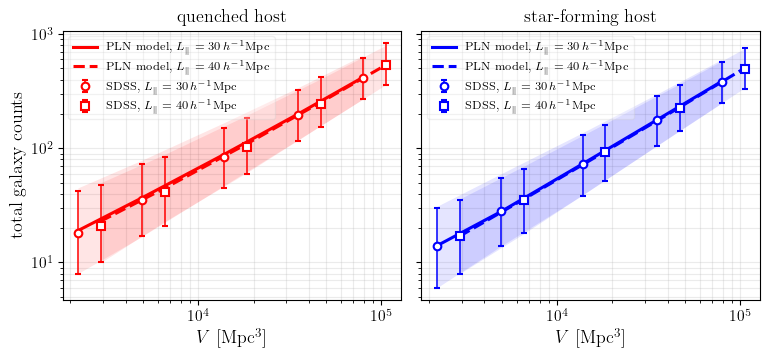

In [15]:
Q_C, SF_C = "red", "blue"
HOST_C = {"Q": Q_C, "SF": SF_C}

Lc = np.array([c[3] for c in cells])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True,
                         gridspec_kw=dict(wspace=0.06))

for ax, (host, title) in zip(axes, [("Q", "quenched host"), ("SF", "star-forming host")]):
    V, emp, mod, eerr = store[host]
    c = HOST_C[host]
    # one curve, band and marker per cylinder length: the model is evaluated at each
    # cylinder's own (R_perp, L_par), not at a single shape
    groups = [(Lc == Lv, mk, ls, f", $L_\\parallel={Lv:.0f}\\,h^{{-1}}$Mpc")
              for Lv, mk, ls in zip(sorted(set(Lc)), "osD^v", ("-", "--", ":", "-."))]
    for m, mk, ls, lab in groups:
        ax.fill_between(V[m], mod[m, 0], mod[m, 2], color=c, alpha=.10, lw=0)
        ax.plot(V[m], mod[m, 1], color=c, lw=2.2, ls=ls, label="PLN model" + lab)
        ax.errorbar(V[m], emp[m, 1], yerr=[emp[m, 1]-emp[m, 0], emp[m, 2]-emp[m, 1]],
                    fmt=mk, ms=5.5, color=c, mfc="w", mew=1.5, capsize=2,
                    elinewidth=1.1, ls="none", zorder=5, label="SDSS" + lab)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$V$   [Mpc$^3$]", fontsize=13)
    ax.set_title(title, fontsize=13)
    ax.grid(alpha=.25, which="both"); ax.set_axisbelow(True)
    ax.legend(fontsize=8.5, loc="upper left", framealpha=0.3)

axes[0].set_ylabel("total galaxy counts" if INCLUDE_HOST
                   else r"neighbouring galaxies $N_{\rm tot}$", fontsize=13)

stem = f"count_distribution_Lpar{L_MIN:.0f}"
if INCLUDE_HOST:
    stem = stem.replace("count_distribution", "count_distribution_withhost")
if SAVE:
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{stem}.{ext}", dpi=160, bbox_inches="tight")
    print("wrote", (OUT / f"{stem}.pdf").relative_to(ROOT))
plt.show()

## How good is it, in numbers

`|z|` is the deviation in units of the jackknife error on the measured percentile.
`max |ratio-1|` is what a statement like *"agree to within about 10%"* rests on.

In [16]:
for host in ("Q", "SF"):
    V, emp, mod, eerr = store[host]
    for k, q in enumerate(QS):
        rat = emp[:, k]/mod[:, k]
        er  = np.where(eerr[:, k] > 0, eerr[:, k]/mod[:, k], np.nan)
        z   = (rat - 1.0)/er
        print(f"  {host:2s} P{q:3d}: med={np.median(rat):.3f}  "
              f"range=[{rat.min():.3f},{rat.max():.3f}]  "
              f"median |z|={np.nanmedian(np.abs(z)):4.2f}  "
              f"within 1 sigma: {int(np.nansum(np.abs(z) < 1))}/{len(rat)}")
worst = max(np.max(np.abs(store[h][1]/store[h][2] - 1)) for h in ("Q", "SF"))
print(f"\nmax |ratio-1| over all selected cells and percentiles: {100*worst:.1f}%")

  Q  P 16: med=0.980  range=[0.913,1.000]  median |z|=0.45  within 1 sigma: 8/10
  Q  P 50: med=0.951  range=[0.911,0.993]  median |z|=0.58  within 1 sigma: 8/10
  Q  P 84: med=0.944  range=[0.904,1.051]  median |z|=0.46  within 1 sigma: 9/10
  SF P 16: med=0.987  range=[0.974,1.000]  median |z|=0.30  within 1 sigma: 7/10
  SF P 50: med=0.993  range=[0.972,1.000]  median |z|=0.14  within 1 sigma: 10/10
  SF P 84: med=0.963  range=[0.917,1.004]  median |z|=0.47  within 1 sigma: 9/10

max |ratio-1| over all selected cells and percentiles: 9.6%
